# Hydrogen's Four n = 2 Wavefunctions: Unit Vectors, Polar Areas, 3D, 4D, Hertz, and Taylor on CUDA

**Colin Casey, 2026.** Library: `dgs/hydrogen_n2_polar.py` (tests: `tests/test_hydrogen_n2_polar.py`), building on `dgs/hydrogen_atom.py`. C and CUDA: `projects/hydrogen_taylor/` (`taylor.c`, `taylor.cu`, `build.bat`).

## In plain words

* **Four possible wavefunctions.** Hydrogen's second shell has exactly four orbital states: 2s, 2p₋₁, 2p₀, 2p₊₁. They behave like **unit vectors**: each has length 1, and every pair is perpendicular. The "length" is an integral over space.
* **Area under the curve in polar coordinates.** In spherical coordinates a volume element is $r^2\sin\theta\,dr\,d\theta\,d\phi$. The curve whose area is 1 is $P(r)=r^2|R(r)|^2$, not $|R|^2$.
* **2D signal + color = 3D.** A slice of $|\psi|^2$ drawn in color already carries three numbers per point. **+ time = 4D.** A 1s + 2p₀ superposition sloshes at $2.47\times10^{15}$ **Hz**: the oscillating dipole that emits 121.6 nm light.
* **Log-scale energy.** $E=hf$ spans from the 21 cm radio line (6 µeV) to ionization (13.6 eV), so it's plotted on log axes.
* **`#include <math.h>`.** $e^{-r/2}$ by Taylor series, in Python, C, and **CUDA** on the RTX 4060, with the classic floating-point trap and its fix.
* **Continuous QM in logic design.** Where the continuous Schrödinger equation meets discrete 0/1 logic.

| your fragment | section |
|---|---|
| "unit vectors 4 possible wavefunction" | §1 |
| "area under curve in polar qm model", "hydrogen field vectors" | §2 |
| "2D signal + color = 3D" | §3 |
| "4D", "animation first simulation", "Hit hertz" | §4 |
| "logscale energy" | §5 |
| "#include math.h", "cuda taylor series computer science", "lint" | §6 |
| "continuous quantum mechanics direction in logic design?" | §7 |

Kernel: **py312**. Atomic units ($a_0=1$, energies in hartree) unless labeled.

In [1]:
import subprocess, pathlib, re
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, Math, Image
from dgs import hydrogen_n2_polar as h
from dgs import hydrogen_atom as ha
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
LABEL = {(2, 0, 0): '2s', (2, 1, -1): '2p_{-1}', (2, 1, 0): '2p_0', (2, 1, 1): '2p_{+1}', (1, 0, 0): '1s'}

## 1. Four wavefunctions = four orthonormal unit vectors (SymPy)

$\psi_{nlm}=R_{nl}(r)\,Y_l^m(\theta,\phi)$. The inner product is $\langle a|b\rangle=\int a^*b\;r^2\sin\theta\,dr\,d\theta\,d\phi$. A Gram matrix equal to the identity means: unit length, mutually perpendicular. The ordinary spherical unit vectors $\hat r,\hat\theta,\hat\phi$ pass the same test in 3D.

In [2]:
for s_ in h.N2_STATES:
    display(Math(r'\psi_{' + LABEL[s_] + '} = ' + sp.latex(sp.simplify(h.psi_sym(*s_)))))
print(f"shell n=2 has {ha.degeneracy(2)} orbital states (dgs.hydrogen_atom.degeneracy), {ha.degeneracy(2, include_spin=True)} with spin")
G = h.gram_matrix()
display(Math(r'\big[\langle\psi_i|\psi_j\rangle\big]_{2s,2p_{-1},2p_0,2p_{+1}} = ' + sp.latex(G)))
vecs, G3 = h.spherical_unit_vectors()
display(Math(r'\hat r = ' + sp.latex(vecs[0].T) + r',\ \hat\theta = ' + sp.latex(vecs[1].T) + r',\ \hat\phi = ' + sp.latex(vecs[2].T)))
display(Math(r'\big[\hat e_i\cdot\hat e_j\big] = ' + sp.latex(G3)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

shell n=2 has 4 orbital states (dgs.hydrogen_atom.degeneracy), 8 with spin


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. Area under the curve in polar coordinates

The angular parts integrate to 1 on their own, so all that's left is the radial integral $\int_0^\infty r^2|R_{nl}|^2dr$. Drop the Jacobian $r^2$ and the "probability" comes out wrong.

,state,area_with_r2,area_without_r2,most_probable_r_a0,nodes_a0
0,1s,1,2,1,[]
1,2s,1,1/4,sqrt(5) + 3,[2]
2,2p,1,1/12,4,[]


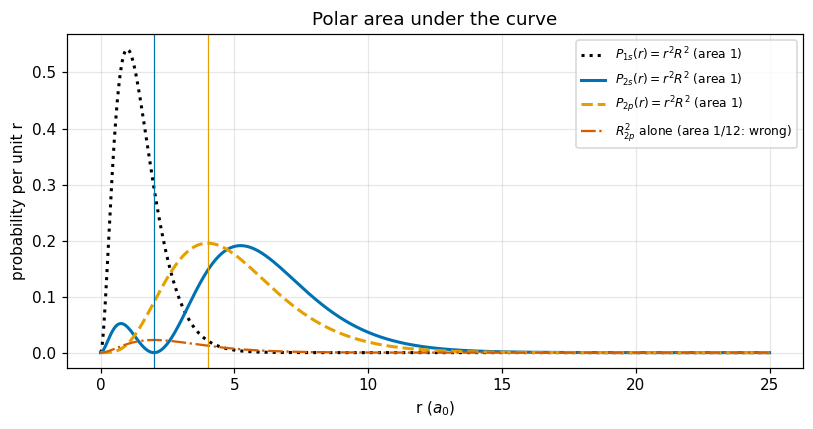

Figure 1. Radial probability densities: 1s (dotted black) peaks at 1 a0, 2p (dashed orange) at 4 a0 (thin orange line), 2s (solid blue) has a node at 2 a0 (thin blue line) and its main peak at 3+sqrt(5) = 5.24 a0. Each encloses area 1. The dash-dot red curve is R_2p^2 without the r^2 Jacobian: it encloses only 1/12, the classic polar-coordinates mistake.


In [3]:
rows = []
for nl, name in [((1, 0), '1s'), ((2, 0), '2s'), ((2, 1), '2p')]:
    rows.append(dict(state=name, area_with_r2=str(h.radial_area(*nl)), area_without_r2=str(h.radial_area(*nl, with_jacobian=False)),
                     most_probable_r_a0=str(h.most_probable_radius(*nl)), nodes_a0=str(h.radial_nodes(*nl))))
display(pd.DataFrame(rows))
r = np.linspace(0, 25, 2000)
fig, ax = plt.subplots(figsize=(7.5, 4))
for (nl, name, c, ls) in [((1, 0), '1s', OI['black'], ':'), ((2, 0), '2s', OI['blue'], '-'), ((2, 1), '2p', OI['orange'], '--')]:
    ax.plot(r, r**2*h.radial(*nl, r)**2, ls, color=c, lw=2, label=f'$P_{{{name}}}(r)=r^2R^2$ (area 1)')
ax.plot(r, h.radial(2, 1, r)**2, '-.', color=OI['red'], label='$R_{2p}^2$ alone (area 1/12: wrong)')
ax.axvline(4, color=OI['orange'], lw=0.8); ax.axvline(2, color=OI['blue'], lw=0.8)
ax.set(xlabel='r ($a_0$)', ylabel='probability per unit r', title='Polar area under the curve'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Radial probability densities: 1s (dotted black) peaks at 1 a0, 2p (dashed orange) at 4 a0 (thin orange line), '
      '2s (solid blue) has a node at 2 a0 (thin blue line) and its main peak at 3+sqrt(5) = 5.24 a0. Each encloses area 1. The '
      'dash-dot red curve is R_2p^2 without the r^2 Jacobian: it encloses only 1/12, the classic polar-coordinates mistake.')

## 3. 2D signal + color = 3D

Slice $|\psi|^2$ on the $y=0$ plane and use color for the value: two coordinates plus a color give three numbers per point. Next to it, the same 2s slice drawn as a height surface shows that color and height carry the same information. $|2p_{\pm1}|^2\propto\sin^2\theta$ are identical "donuts": $m=\pm1$ differ only in phase $e^{\pm i\phi}$, which $|\psi|^2$ can't see. That's the phase-retrieval problem again.

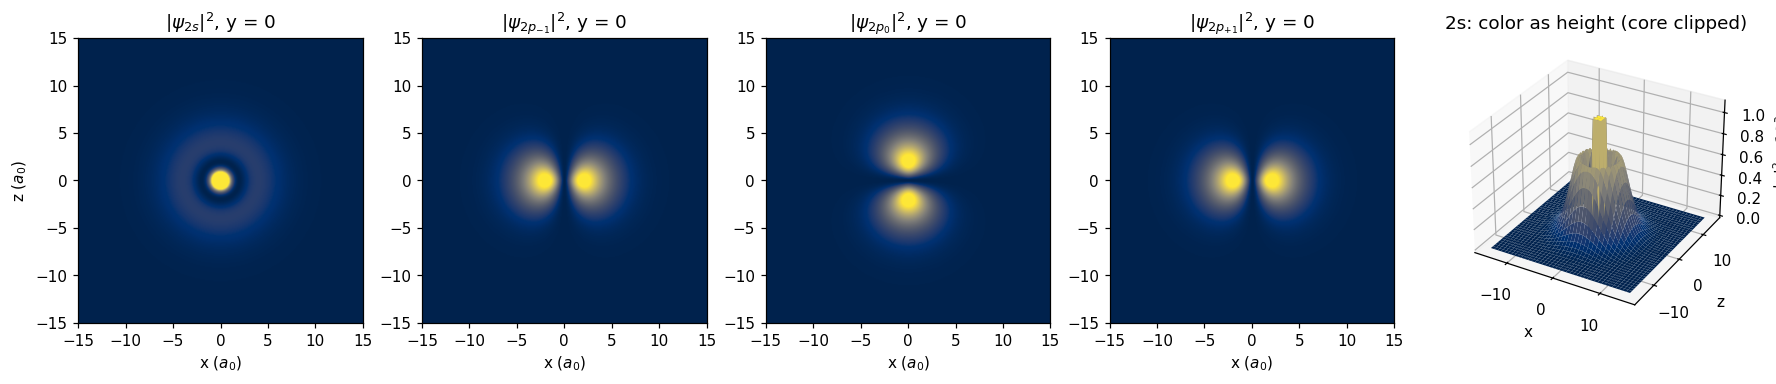

Figure 2. Probability density on the y = 0 plane (cividis: dark low, yellow high) for 2s, 2p-1, 2p0, 2p+1, and the 2s slice again as a 3D height surface with the central peak clipped so the outer ring is visible. 2s: bright core, dark node ring at r = 2, faint outer ring. 2p0: two lobes along z with a nodal plane z = 0. 2p+-1: identical side lobes (a donut around z), because m = +1 and -1 differ only in phase.


In [4]:
fig = plt.figure(figsize=(16, 3.8))
for i, s_ in enumerate(h.N2_STATES):
    axi = fig.add_subplot(1, 5, i + 1)
    ax_, rho = h.density_slice_xz({s_: 1.0}, extent=15, n=301)
    axi.imshow(rho, origin='lower', extent=[-15, 15, -15, 15], cmap='cividis', vmax=np.percentile(rho, 99.7))
    axi.set(title=f'$|\\psi_{{{LABEL[s_]}}}|^2$, y = 0', xlabel='x ($a_0$)', ylabel='z ($a_0$)' if i == 0 else None)
    axi.grid(False)
ax3d = fig.add_subplot(1, 5, 5, projection='3d')
ax_, rho = h.density_slice_xz({(2, 0, 0): 1.0}, extent=15, n=121)
Xg, Zg = np.meshgrid(ax_, ax_)
cap = rho[np.hypot(Xg, Zg) > 4].max()*1.5
ax3d.plot_surface(Xg, Zg, np.minimum(rho, cap)*1e3, cmap='cividis', linewidth=0)
ax3d.set(title='2s: color as height (core clipped)', xlabel='x', ylabel='z', zlabel='$|\\psi|^2\\times10^3$')
plt.tight_layout(); plt.show()
print('Figure 2. Probability density on the y = 0 plane (cividis: dark low, yellow high) for 2s, 2p-1, 2p0, 2p+1, and the 2s '
      'slice again as a 3D height surface with the central peak clipped so the outer ring is visible. 2s: bright core, dark '
      'node ring at r = 2, faint outer ring. 2p0: two lobes along z with a nodal plane z = 0. 2p+-1: identical side lobes (a '
      'donut around z), because m = +1 and -1 differ only in phase.')

## 4. + time = 4D: the 1s + 2p₀ dipole, in hertz

$\Psi=\tfrac1{\sqrt2}\big(\psi_{1s}e^{-iE_1t}+\psi_{2p_0}e^{-iE_2t}\big)$. The cross term beats at the Bohr frequency $(E_2-E_1)/h$, so the electron cloud sloshes along $z$ with $\langle z\rangle(t)=2\,\mathrm{Re}\big(c_1^*c_2\,\langle1s|z|2p_0\rangle e^{-i\omega t}\big)$, where $\langle1s|z|2p_0\rangle=128\sqrt2/243\ a_0$. A sloshing charge radiates: this is Lyman-α. A 2s + 2p₀ superposition does **not** move, because both have the same energy.

Bohr frequency: 2.4674e+15 Hz (period 0.405 fs = 16.76 atomic time units); wavelength 121.5 nm
2s+2p0 stationary? max change over 1/3 period: 3.5e-18


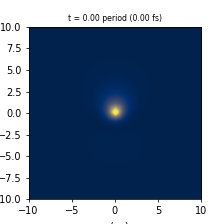

Animation (4D: x, z, color, time) saved to hydrogen_1s2p_dipole.gif: one full period of the 1s+2p0 density, 24 frames.


In [5]:
w = h.energy_ha(2) - h.energy_ha(1)
T_au = 2*np.pi/w
f_hz = h.bohr_frequency_hz(2, 1)
print(f'Bohr frequency: {f_hz:.4e} Hz (period {1/f_hz*1e15:.3f} fs = {T_au:.2f} atomic time units); wavelength {h.C_LIGHT/f_hz*1e9:.1f} nm')
mix = {(1, 0, 0): 2**-0.5, (2, 1, 0): 2**-0.5}
same = {(2, 0, 0): 2**-0.5, (2, 1, 0): 2**-0.5}
print('2s+2p0 stationary? max change over 1/3 period:',
      f"{np.max(np.abs(h.density_slice_xz(same, n=101, t=0)[1] - h.density_slice_xz(same, n=101, t=T_au/3)[1])):.1e}")
frames = 24
fig, axa = plt.subplots(figsize=(3.2, 3.2), dpi=70)
ax_, rho0 = h.density_slice_xz(mix, extent=10, n=151, t=0)
im = axa.imshow(rho0, origin='lower', extent=[-10, 10, -10, 10], cmap='cividis', vmax=rho0.max()*0.6)
axa.set(xlabel='x ($a_0$)', ylabel='z ($a_0$)'); axa.grid(False)
def upd(k):
    im.set_data(h.density_slice_xz(mix, extent=10, n=151, t=k*T_au/frames)[1])
    axa.set_title(f't = {k/frames:.2f} period ({k/frames/f_hz*1e15:.2f} fs)', fontsize=8)
    return (im,)
anim = animation.FuncAnimation(fig, upd, frames=frames, blit=False)
gif = pathlib.Path.cwd() / 'hydrogen_1s2p_dipole.gif'
anim.save(gif, writer=animation.PillowWriter(fps=8))
plt.close(fig)
display(Image(filename=str(gif)))
print(f'Animation (4D: x, z, color, time) saved to {gif.name}: one full period of the 1s+2p0 density, {frames} frames.')

<IPython.core.display.Math object>

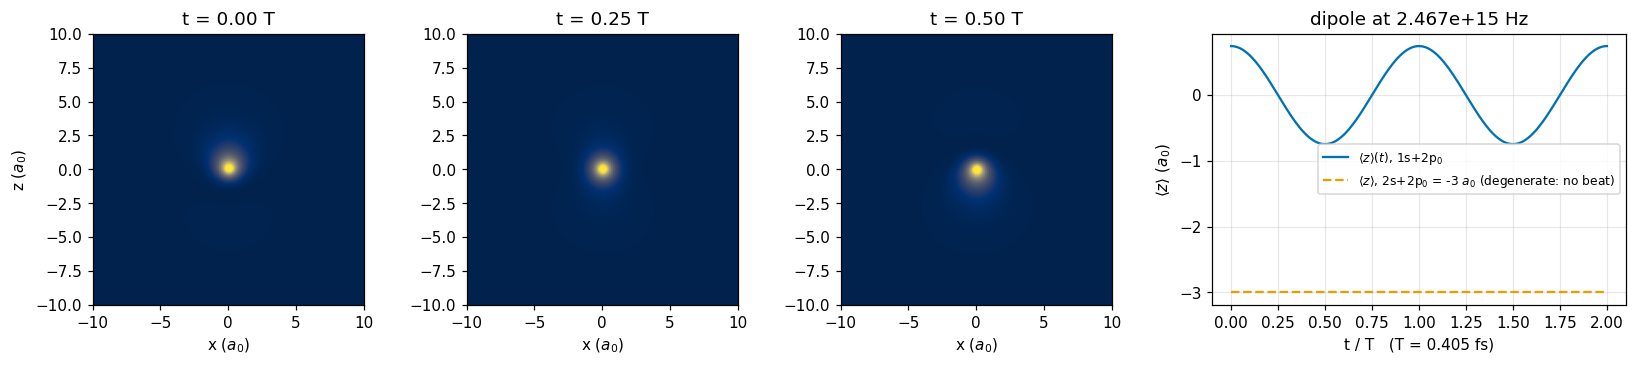

Figure 3. Frames of the 1s+2p0 density at t = 0, T/4, T/2 (period T = 0.405 fs): the cloud sits above the nucleus, then centered, then below. Right: the 1s+2p0 dipole <z>(t) oscillates (solid blue, amplitude 0.745 a0) at the Bohr frequency and radiates; the degenerate 2s+2p0 mixture has a large but CONSTANT dipole of -3 a0 (dashed orange): a permanent dipole with no beat and no radiation, the origin of hydrogen's linear Stark effect.


In [6]:
tt = np.linspace(0, 2*T_au, 400)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.5]))
for i, frac in enumerate([0.0, 0.25, 0.5]):
    ax_, rho = h.density_slice_xz(mix, extent=10, n=151, t=frac*T_au)
    ax[i].imshow(rho, origin='lower', extent=[-10, 10, -10, 10], cmap='cividis', vmax=rho0.max()*0.6)
    ax[i].set(title=f't = {frac:.2f} T', xlabel='x ($a_0$)', ylabel='z ($a_0$)' if i == 0 else None); ax[i].grid(False)
z_2s2p = h.inner_product(h.psi_sym(2, 0, 0), h.r_s*sp.cos(h.th_s)*h.psi_sym(2, 1, 0))
z_deg = float(2*0.5*z_2s2p)
display(Math(r'\langle 2s|z|2p_0\rangle = ' + sp.latex(z_2s2p) + r'\,a_0 \;\Rightarrow\; \langle z\rangle_{(2s+2p_0)/\sqrt2} = ' + sp.latex(z_2s2p) + r'\,a_0\ \text{(constant)}'))
ax[3].plot(tt/T_au, h.dipole_z(tt), '-', color=OI['blue'], label='$\\langle z\\rangle(t)$, 1s+2p$_0$')
ax[3].plot(tt/T_au, np.full_like(tt, z_deg), '--', color=OI['orange'], label=f'$\\langle z\\rangle$, 2s+2p$_0$ = {z_deg:.0f} $a_0$ (degenerate: no beat)')
ax[3].set(xlabel=f't / T   (T = {1/f_hz*1e15:.3f} fs)', ylabel='$\\langle z\\rangle$ ($a_0$)', title=f'dipole at {f_hz:.3e} Hz'); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Frames of the 1s+2p0 density at t = 0, T/4, T/2 (period T = 0.405 fs): the cloud sits above the nucleus, then '
      'centered, then below. Right: the 1s+2p0 dipole <z>(t) oscillates (solid blue, amplitude 0.745 a0) at the Bohr frequency '
      'and radiates; the degenerate 2s+2p0 mixture has a large but CONSTANT dipole of -3 a0 (dashed orange): a permanent dipole '
      'with no beat and no radiation, the origin of hydrogen\'s linear Stark effect.')

## 5. Log-scale energy vs hertz

$E=hf$ is a straight line of slope 1 on log–log axes. Hydrogen alone spans nine decades, from the 21 cm hyperfine line (radio astronomy) to the Lyman limit. A 1 GHz clock tick and room-temperature $kT$ are added for scale: a single 21 cm photon carries about as much energy as one 1 GHz photon, and both are thousands of times smaller than $kT$.

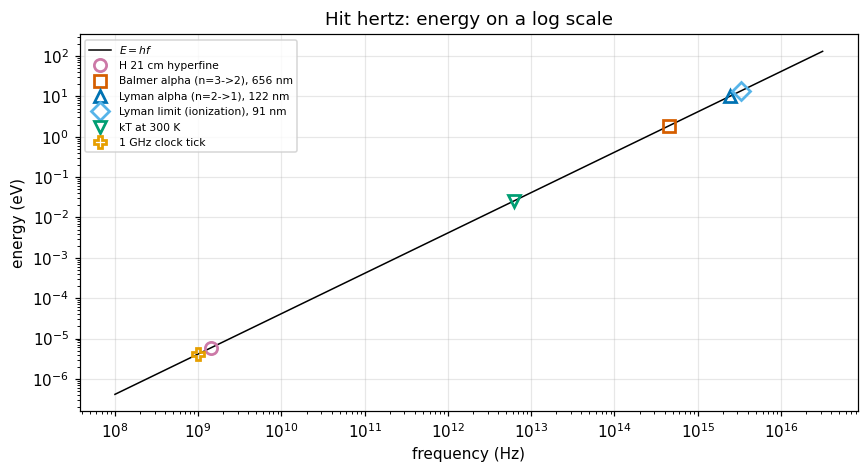

Figure 4. Photon energy against frequency on log-log axes; the black line is E = h f. Markers (each a different shape): the 21 cm hyperfine line and a 1 GHz clock tick near 1e9 Hz / 5e-6 eV, kT at 300 K near 6e12 Hz / 0.026 eV, and the Balmer-alpha, Lyman-alpha, and Lyman-limit lines between 4.6e14 and 3.3e15 Hz.


,name,energy_eV,freq_Hz,wavelength_m
0,H 21 cm hyperfine,0.000006,1.420406e+09,2.110611e-01
1,"Balmer alpha (n=3->2), 656 nm",1.889680,4.569225e+14,6.561123e-07
2,"Lyman alpha (n=2->1), 122 nm",10.204270,2.467381e+15,1.215023e-07
3,"Lyman limit (ionization), 91 nm",13.605693,3.289842e+15,9.112671e-08
4,kT at 300 K,0.025852,6.250986e+12,4.795923e-05
5,1 GHz clock tick,0.000004,1.000000e+09,2.997925e-01


In [7]:
tab = pd.DataFrame(h.spectrum_table())
f = np.logspace(8, 16.5, 100)
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.loglog(f, h.H_EV_S*f, '-', color=OI['black'], lw=1, label='$E = hf$')
mk = ['o', 's', '^', 'D', 'v', 'P']
cols = [OI['purple'], OI['red'], OI['blue'], OI['sky'], OI['green'], OI['orange']]
for (i, row), m_, c_ in zip(tab.iterrows(), mk, cols):
    ax.loglog(row.freq_Hz, row.energy_eV, m_, ms=8, mfc='none', mew=1.8, color=c_, label=row['name'])
ax.set(xlabel='frequency (Hz)', ylabel='energy (eV)', title='Hit hertz: energy on a log scale'); ax.legend(fontsize=7, loc='upper left')
plt.tight_layout(); plt.show()
print('Figure 4. Photon energy against frequency on log-log axes; the black line is E = h f. Markers (each a different shape): '
      'the 21 cm hyperfine line and a 1 GHz clock tick near 1e9 Hz / 5e-6 eV, kT at 300 K near 6e12 Hz / 0.026 eV, and the '
      'Balmer-alpha, Lyman-alpha, and Lyman-limit lines between 4.6e14 and 3.3e15 Hz.')
tab

## 6. `#include <math.h>`: $e^{x}$ by Taylor series, in Python, C, and CUDA

Every radial function contains $e^{-r/2}$. Three ways to get it from $\sum x^k/k!$:

| method | idea | failure mode |
|---|---|---|
| naive | $e^{-x}=\sum(-x)^k/k!$ | terms of size $x^k/k!$ cancel to leave a tiny result: **catastrophic cancellation** |
| stable | $e^{-x}=1/\sum x^k/k!$ | no cancellation, but large $x$ needs many terms |
| range-reduced | $e^x=2^k e^s$, $s=x-k\ln2$, $|s|\le\tfrac12\ln2$ | none: 14 terms reach full double precision (what libm does) |

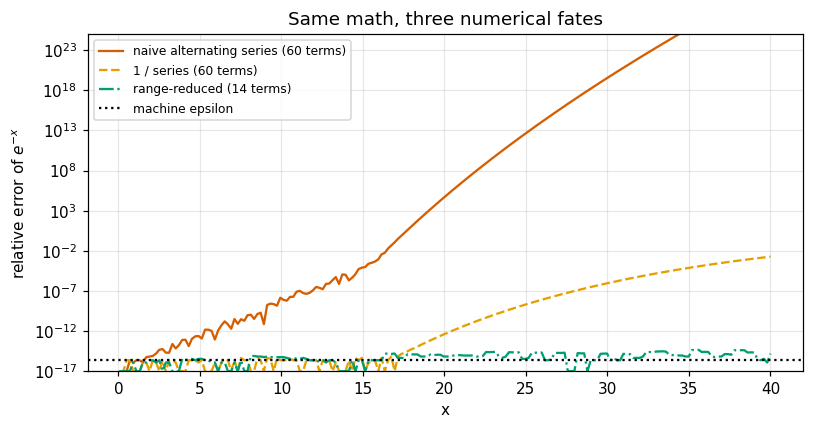

Figure 5. Relative error of e^{-x} against x (log scale). Red (solid): the naive alternating series loses digits steadily, crosses relative error 1 (no correct digits) at x = 17.5, and passes 1e23 by x = 35. Orange (dashed): 1/series is exact until about x = 17, then degrades as 60 terms become too few (1e-3 at x = 40). Green (dash-dot): range reduction stays at machine epsilon (dotted black) everywhere.
Taylor terms needed for 1e-15 relative accuracy of e^x without range reduction: {0.35: 13, 1: 17, 5: 32, 10: 45, 20: 66}


In [8]:
xs = np.linspace(0.1, 40, 200)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogy(xs, np.abs(h.exp_neg_naive(xs)/np.exp(-xs) - 1) + 1e-17, '-', color=OI['red'], label='naive alternating series (60 terms)')
ax.semilogy(xs, np.abs(h.exp_neg_stable(xs)/np.exp(-xs) - 1) + 1e-17, '--', color=OI['orange'], label='1 / series (60 terms)')
ax.semilogy(xs, np.abs(h.exp_range_reduced(-xs)/np.exp(-xs) - 1) + 1e-17, '-.', color=OI['green'], label='range-reduced (14 terms)')
ax.axhline(np.finfo(float).eps, color=OI['black'], ls=':', label='machine epsilon')
ax.set(xlabel='x', ylabel='relative error of $e^{-x}$', ylim=(1e-17, 1e25), title='Same math, three numerical fates'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
naive_err = np.abs(h.exp_neg_naive(xs)/np.exp(-xs) - 1)
x_cross = xs[np.argmax(naive_err > 1)]
print('Figure 5. Relative error of e^{-x} against x (log scale). Red (solid): the naive alternating series loses digits '
      f'steadily, crosses relative error 1 (no correct digits) at x = {x_cross:.1f}, and passes 1e23 by x = 35. Orange (dashed): '
      '1/series is exact until about x = 17, then degrades as 60 terms become too few (1e-3 at x = 40). Green (dash-dot): range '
      'reduction stays at machine epsilon (dotted black) everywhere.')
print('Taylor terms needed for 1e-15 relative accuracy of e^x without range reduction:',
      {x_: h.terms_needed(x_) for x_ in (0.35, 1, 5, 10, 20)})

Now the same algorithms in **C** (`taylor.c`, built as a lint check: `-Wall -Wextra -Wpedantic -Wconversion -Werror`) and **CUDA** (`taylor.cu`: one GPU thread per radius, $2^{20}$ radii, kernel timed with CUDA events). The cell runs `projects/hydrogen_taylor/build.bat` and prints its real output. If a compiler is missing, the output says so.

In [9]:
proj = pathlib.Path.cwd().parent / 'projects' / 'hydrogen_taylor'
r_ = subprocess.run(['cmd', '/c', str(proj / 'build.bat')], capture_output=True, text=True, timeout=900)
log = r_.stdout + r_.stderr
print(log.strip())
print(f'\nbuild.bat exit code: {r_.returncode}')
def grab(key):
    m_ = re.search(rf'^{key}, ([^\n]+)', log, flags=re.M)
    return m_.group(1).strip() if m_ else None
c_ok = grab('area_P2p') is not None
gpu_ok = grab('kernel_ms') is not None
print(f"C program ran: {c_ok}; GPU program ran: {gpu_ok}" + (f" on {grab('device')}" if gpu_ok else ''))

=== C11 + math.h (gcc lint: -Wall -Wextra -Wpedantic -Wconversion -Werror) ===
built taylor_c.exe
x, rel_err_naive, rel_err_stable, rel_err_reduced
1, 0.000e+00, 0.000e+00, 0.000e+00
5, -2.459e-13, 0.000e+00, -2.220e-16
10, 2.446e-09, -1.110e-16, -5.551e-16
20, -5.057e+04, 4.232e-13, 8.882e-16
30, -3.643e+19, 9.252e-07, -1.665e-15
area_P2s, 1.000000000000
area_P2p, 1.000000000000
P2p_peak_r4, 0.195366814813 (exact 4^4 e^-4 / 24 = 0.195366814813)
=== CUDA (nvcc, sm_89) ===
taylor.cu
tmpxft_00003388_00000000-7_taylor.cudafe1.cpp
built taylor_gpu.exe
device, NVIDIA GeForce RTX 4060
points, 1048576
kernel_ms, 1.2913
max_rel_err_P2p_vs_libm, 3.109e-15
area_P2s, 0.999999999999
area_P2p, 0.999999999999
Build OK.

build.bat exit code: 0
C program ran: True; GPU program ran: True on NVIDIA GeForce RTX 4060


## 7. Continuous quantum mechanics → logic design?

**The tension.** The Schrödinger equation is *continuous*: amplitudes are complex numbers and energies form a continuum unless something confines them. Logic is *discrete*: 0/1. Quantization is the bridge. Confinement (a box, an atom, a superconducting circuit) turns the continuum into a discrete ladder, and engineers pick **two rungs** as a bit or a qubit, as the 2s/2p levels here or a transmon's lowest two states.

Three ways that thread runs into logic design:

1. **Inside today's chips (continuous QM as a constraint).** Gate-oxide tunneling, the triangular inversion-layer well (`steam3d_qm_classifier.ipynb`), and quantized FinFET subbands. Designers fight the continuous wave mechanics to keep 0 and 1 clean. The thermodynamic floor for *erasing* a bit is Landauer's $k_BT\ln2$ (computed below).
2. **Discrete-variable quantum logic (qubits).** Two levels per element, gates as $2\times2$/$4\times4$ unitaries. Your "4 possible wavefunctions" is exactly a 4-dimensional state space, the same size as **two qubits** ($|00\rangle,|01\rangle,|10\rangle,|11\rangle$).
3. **Continuous-variable (CV) quantum computing.** Keep the continuum: information lives in the *quadratures* $\hat x,\hat p$ of a harmonic oscillator (a light mode), and gates are Gaussian operations (displacements, squeezing, beam splitters) plus one non-Gaussian element [3]. To get fault-tolerant logic, the **GKP code** [4] embeds a qubit in the continuous oscillator as a grid of narrow peaks. This is the most direct "continuous QM → logic" path, and it's photonic, which is the natural home of dispersion and time-stretch.

**Design direction for this repo:** time-stretch measures a continuous optical field, and GS phase retrieval recovers its continuous phase. A CV photonic processor needs exactly that kind of continuous-field readout. The discrete/continuous boundary is where the receiver design work sits.

In [10]:
kB_eV = 8.617333262e-5
landauer = kB_eV*300*np.log(2)
print(f'Landauer limit at 300 K: kT ln2 = {landauer*1e3:.2f} meV = {landauer*1.602176634e-19:.3e} J per erased bit')
print(f'  = {landauer/abs(ha.transition_energy(2, 1)):.2e} of a Lyman-alpha photon; = {landauer/(h.H_EV_S*1e9):.0f} photons of 1 GHz')
print('Two qubits span 4 basis states, the same dimension as hydrogen n=2 without spin (Sec. 1).')

Landauer limit at 300 K: kT ln2 = 17.92 meV = 2.871e-21 J per erased bit
  = 1.76e-03 of a Lyman-alpha photon; = 4333 photons of 1 GHz
Two qubits span 4 basis states, the same dimension as hydrogen n=2 without spin (Sec. 1).


**References** (from memory; verify before citing)
[1] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018, ch. 4.
[2] D. Goldberg, "What every computer scientist should know about floating-point arithmetic," *ACM Comput. Surv.*, vol. 23, no. 1, pp. 5–48, 1991.
[3] S. Lloyd and S. L. Braunstein, "Quantum computation over continuous variables," *Phys. Rev. Lett.*, vol. 82, no. 8, pp. 1784–1787, 1999.
[4] D. Gottesman, A. Kitaev, and J. Preskill, "Encoding a qubit in an oscillator," *Phys. Rev. A*, vol. 64, no. 1, Art. no. 012310, 2001.
[5] R. Landauer, "Irreversibility and heat generation in the computing process," *IBM J. Res. Develop.*, vol. 5, no. 3, pp. 183–191, 1961.

**Limitations.**
- Non-relativistic hydrogen only, with no fine structure, Lamb shift or spin. The 2s/2p degeneracy is exact only in this model; the real Lamb shift splits it by about 1 GHz.
- The animation ignores radiative decay.
- The CUDA timing is one measurement on this machine.
- §7 is a written overview, not a simulation.